# Compare and detection

Reproduces the **Compare** and **Why detection fails** pages of Close & Distant. Every function used here lives in `analysis/features.py`, which mirrors the browser code.

In [1]:
import json, sys, statistics
from collections import Counter
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "../analysis")
from features import *

DATA = Path("../web/public/data")
essays = json.loads((DATA / "essays.json").read_text())["essays"]
wordlist = set(json.loads((DATA / "wordlist.json").read_text()))
markers = json.loads((DATA / "markers.json").read_text())
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TEAL, OCHRE, INK = "#008f86", "#b07d12", "#1c2b3a"


## Style profile of every essay

In [2]:
rows = []
for e in essays:
    p = profile(e["text"], wordlist, markers)
    p.update(id=e["id"], source=e["source"], prompt=e["prompt"],
             group=e.get("band") or e["condition"], proficiency=e.get("proficiency"))
    rows.append(p)
df = pd.DataFrame(rows)
df.groupby("source").mean(numeric_only=True).T

source,human,llm
tokens,423.850,213.917
sentences,18.283,14.833
meanSentenceLength,27.317,14.476
sentenceLengthCV,0.538,0.409
meanWordLength,4.357,5.205
mattr,0.752,0.877
offListPct,9.260,18.258
hedges,7.543,8.280
boosters,4.079,4.443
connectives,5.904,7.957


## Group means by learner proficiency band and model instruction

In [3]:
FEATS = ["meanWordLength", "mattr", "offListPct", "meanSentenceLength", "sentenceLengthCV",
         "hedges", "boosters", "connectives", "selfMention"]
df.groupby("group")[FEATS].mean().T

group,concise,default,higher,lower,middle,persuade,student
meanWordLength,5.732,5.465,4.452,4.239,4.380,5.441,4.182
mattr,0.874,0.888,0.779,0.737,0.740,0.890,0.856
offListPct,25.029,20.343,9.394,10.730,7.658,22.080,5.579
meanSentenceLength,14.564,15.122,25.667,31.929,24.355,13.727,14.490
sentenceLengthCV,0.393,0.425,0.493,0.588,0.534,0.441,0.379
hedges,1.344,11.964,9.701,6.452,6.475,0.683,19.129
boosters,1.792,2.704,6.984,2.376,2.877,3.378,9.897
connectives,9.581,11.452,6.389,5.220,6.102,6.859,3.936
selfMention,0.000,7.959,19.657,29.139,19.563,5.684,47.062


## Keyness: learners against the model

Log-likelihood ≥ 6.63 (p < .01).

In [4]:
tH = [w for e in essays if e["source"] == "human" for w in tokens(e["text"])]
tM = [w for e in essays if e["source"] == "llm" for w in tokens(e["text"])]
key = pd.DataFrame(keyness(tH, tM, 5))
key = key[key.ll >= 6.63]
print("More typical of learners:", ", ".join(key[key.logRatio > 0].word.head(15)))
print("More typical of the model:", ", ".join(key[key.logRatio < 0].word.head(15)))

More typical of learners: you, have, they, because, the, he, take, your, do, to, contact, not, conferencing, taking, why
More typical of the model: learning, digital, distance, tools, access, these, allow, advanced, communities, concerns, connection, flexibility, privacy, reduce, improves


## The naive detector

In [5]:
df["score"] = detector_scores(df.to_dict("records"))
is_llm = df.source == "llm"
acc = lambda t: ((df.score >= t) == is_llm).mean()
best = max(sorted(df.score), key=acc)   # lowest threshold reaching the best accuracy
catch_all = df[is_llm].score.min()
for name, t in [("best accuracy", best), ("catch every model essay", catch_all)]:
    flagged = df.score >= t
    print(f"{name}: threshold {t:.2f}, accuracy {acc(t):.0%}, model flagged {flagged[is_llm].mean():.0%}, "
          f"learners flagged {flagged[~is_llm].mean():.0%}")
    print(df.assign(flagged=flagged).groupby("group").flagged.mean().round(2).to_dict())

best accuracy: threshold 0.80, accuracy 93%, model flagged 75%, learners flagged 0%
{'concise': 1.0, 'default': 1.0, 'higher': 0.0, 'lower': 0.0, 'middle': 0.0, 'persuade': 1.0, 'student': 0.0}
catch every model essay: threshold -0.48, accuracy 42%, model flagged 100%, learners flagged 82%
{'concise': 1.0, 'default': 1.0, 'higher': 0.85, 'lower': 0.75, 'middle': 0.85, 'persuade': 1.0, 'student': 1.0}


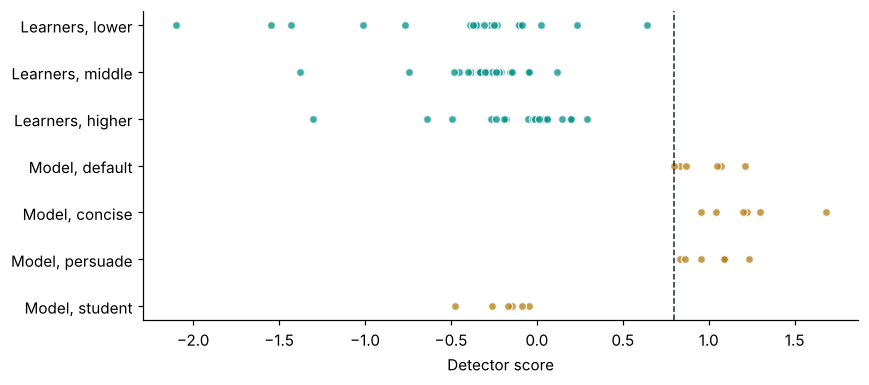

In [6]:
order = ["lower", "middle", "higher", "default", "concise", "persuade", "student"]
fig, ax = plt.subplots(figsize=(8, 3.6))
for i, g in enumerate(order):
    s = df[df.group == g].score
    ax.scatter(s, [i] * len(s), color=TEAL if g in order[:3] else OCHRE, alpha=0.75, s=28, edgecolor="white")
ax.axvline(best, color=INK, ls="--", lw=1)
ax.set_yticks(range(len(order)), [f"Learners, {g}" if g in order[:3] else f"Model, {g}" for g in order])
ax.invert_yaxis(); ax.set_xlabel("Detector score"); plt.tight_layout()

In [7]:
print("Correlation between learner proficiency and detector score:",
      round(df[~is_llm][["proficiency", "score"]].corr().iloc[0, 1], 3))

Correlation between learner proficiency and detector score: 0.169
